# Object Localisatie

In deze notebook gaan we twee kernconcepten van computer vision implementeren: object localisatie en object detectie. We gebruiken hiervoor zowel zelf te trainen netwerken als pre-trained netwerken om de taken te voltooien. Object localisatie is gericht op het vinden van de positie van een enkel object in een afbeelding, terwijl object detectie het vinden van meerdere objecten met hun bijbehorende klassen omvat.
Onderstaande code-cel bevat een reeks imports en twee helper functies voor visualisatie. Deze gaan we later gebruiken voor visualisatie.

In [1]:
import os
import xml.etree.ElementTree as ET
import torch
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import kagglehub
import numpy as np

path = kagglehub.dataset_download("mbkinaci/image-localization-dataset")

# Helper Functies
def imshow(img, title=None):
    """Toont een afbeelding."""
    npimg = img.numpy() if isinstance(img, torch.Tensor) else img
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    if title:
        plt.title(title)
    plt.show()

def show_image_with_bbox(image, bbox, title=None):
    """Toont een afbeelding met een bounding box."""
    npimg = image.numpy() if isinstance(image, torch.Tensor) else image
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    img_size = npimg.shape[1]
    xmin = bbox[0] * img_size
    ymin = bbox[1] * img_size
    xmax = bbox[2] * img_size
    ymax = bbox[3] * img_size
    print(xmin, ymin, xmax, ymax)
    plt.gca().add_patch(plt.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                                      fill=False, edgecolor='red', linewidth=2))
    if title:
        plt.title(title)
    plt.show()

## Oefening 1: Object Localisatie met PyTorch

In deze oefening gebruiken we PyTorch om een eenvoudig neuraal netwerk te trainen voor object localisatie. Het doel van object localisatie is om de coördinaten van de bounding box rondom een enkel object in een afbeelding te voorspellen. We maken een convolutioneel neuraal netwerk (CNN) dat leert om vier waarden te voorspellen: de x- en y-coördinaten van de bovenste linkerhoek van de bounding box, en de breedte en hoogte van de box. 

We gebruiken de dataset die hierboven is ingeladen en foto's bevat van een aantal soorten groenten.
De path variabele bevat het absolute pad naar de dataset en kan gebruikt worden om de data in te laden.
Alle data zit in een subfolder training_images en bevat twee bestanden per voorbeeld.

* Een jpg-bestand met de figuur
* Een xml-bestand met de klasse en een bounding box.

Met onderstaande figuur toon ik een figuur uit de dataset als voorbeeld hoe je aan de bestanden kan geraken.

Daarna is het de bedoeling dat je zelf een XML-dataset maakt die de jpg-bestanden en xml-bestanden inleest.
In de `__getitem__` functie moet de figuur en xml ingelezen worden. De volgende stappen moeten gebeuren in deze functie:
* lees de image in
* zet het om naar een tensor, resize het naar een figuur van 128 pixels bij 128 en normalizeer de figuur (hiervoor kunnen de volgende waarden gebruikt worden: `mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]`).
* Lees de xml-fgiuur in met behulp van de xml package
* Extract de 4 waarden van de bounding box en zet deze waarden om naar percentages van de breedte en hoogte. **Waarom is het omzetten naar percentages belangrijk?**
* Return de getransformeerde figuur als input en de tensor met de 4 bounding box waarden als output

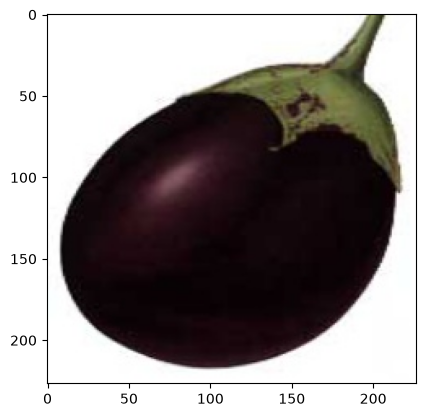

In [2]:
path = os.path.join(path, "training_images")
images=[f for f in os.listdir(path) if f.endswith(".jpg")]
plt.imshow(Image.open(os.path.join(path, images[1])))

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7900449..2.640001].


tensor([[0.1278, 0.1586, 0.7533, 0.8722],
        [0.2026, 0.1894, 0.7665, 0.8018],
        [0.0617, 0.1938, 0.9163, 0.9031],
        [0.0352, 0.3128, 0.9471, 0.6696],
        [0.2335, 0.1233, 0.8238, 0.9207],
        [0.1806, 0.2555, 0.7885, 0.6916],
        [0.1057, 0.1145, 0.8811, 0.8678],
        [0.2291, 0.1013, 0.9383, 0.8899]])
tensor(2.6400)
tensor(7.8943) tensor(24.8106) tensor(117.2863) tensor(115.5947)


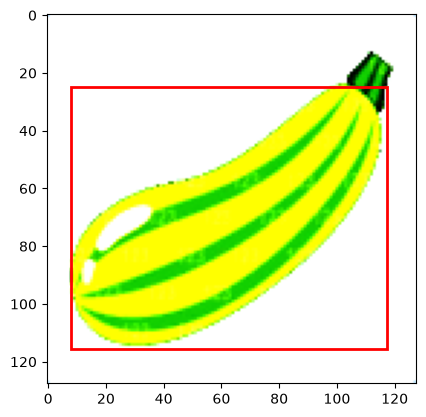

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),  # Zet de afbeelding om naar een tensor en normaliseer naar [0, 1]
    transforms.Resize((128,128)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# custom dataset aanmaken
class XMLDataset(Dataset):
    def __init__(self, root_dir, transform=None, img_size=128):
        self.root_dir = root_dir
        self.transform = transform
        self.img_size=img_size

        self.images=[f for f in os.listdir(self.root_dir) if f.endswith(".jpg")]
        pass

    def __len__(self):
        return len(self.images)
        
    def __getitem__(self, idx):
        # read image
        img_path = os.path.join(self.root_dir, self.images[idx])
        image = Image.open(img_path)

        if self.transform:
            image = self.transform(image)

        # extract bbox
        xml_path = os.path.splitext(img_path)[0] + '.xml' # vervang .jpg door .xml
        tree = ET.parse(xml_path)
        root = tree.getroot() # parse xml file

        width = float(root.find('size/width').text)
        height = float(root.find('size/height').text)
        
        bbox = root.find('object/bndbox')
        xmin = float(bbox.find('xmin').text) # haal de waarde uit de node op
        xmax = float(bbox.find('xmax').text)
        ymin = float(bbox.find('ymin').text)
        ymax = float(bbox.find('ymax').text)

        # preprocess bbox
        # zet het om naar x en y linkerboven hoek en breedte/hoogte van de bbxo
        # zet het om naar percentages
        bbox = [xmin/width, ymin/height, xmax/width, ymax/height]
        
        # return image,bbox
        return image, torch.tensor(bbox, dtype=torch.float32)

dataset = XMLDataset(root_dir=path, transform=transform, img_size=128)
dataloader = DataLoader(dataset, batch_size=8, shuffle=True)

for image, output in dataloader:
    print(output)
    print(torch.max(image[2]))
    show_image_with_bbox(image[2], output[2])
    break

In [4]:
# Kies device: GPU indien beschikbaar, anders CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


model = nn.Sequential(
    #convolutioneel gedeelte
    nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1, stride=1), # out_channels kan je kiezen, typisch wordt dit groter als je dieper in het netwerk gaat
    nn.ReLU(), # de activatiefunctie!
    nn.MaxPool2d(2),
    nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1, stride=1), # in_channels gelijk aan out_channels vorige
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1, stride=1), 
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1, stride=1), 
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1, stride=1), 
    nn.ReLU(),
    nn.MaxPool2d(2),
    #Flatten (maak er 1d van van elk figuur)
    nn.Flatten(),
    #Fully connected gedeelte
    nn.Linear(16*64, 128),  # 16384 te berekenen door het model eens uit te voeren tot de flatten of 16*16*64
    nn.ReLU(),
    nn.Linear(128, 4),
    nn.Sigmoid() # kan toegevoegd worden om waarden te hebben tussen 0 en 1
).to(device)

for image,target in dataloader:
    print(model(image.to(device)).shape)
    break

Using device: cuda
torch.Size([8, 4])


In [5]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 50

for epoch in range(num_epochs):
    epoch_loss = 0.0
    for image,target in dataloader:
        image, target = image.to(device),target.to(device)
        optimizer.zero_grad()
        outputs = model(image)
        loss = criterion(outputs, target)
        loss.backward()
        optimizer.step()
        epoch_loss+= loss.item()

    print(f"Epoch {epoch}: running loss is {epoch_loss / len(dataloader)}")

Epoch 0: running loss is 0.04024589139347275
Epoch 1: running loss is 0.014426264310410867
Epoch 2: running loss is 0.012137371192996701
Epoch 3: running loss is 0.012188005416343609
Epoch 4: running loss is 0.011680441656305144
Epoch 5: running loss is 0.011805768706835806
Epoch 6: running loss is 0.011437256044397751
Epoch 7: running loss is 0.009654794843906226
Epoch 8: running loss is 0.007251059229020029
Epoch 9: running loss is 0.006635669381163704
Epoch 10: running loss is 0.005815132986754179
Epoch 11: running loss is 0.005104932264657691
Epoch 12: running loss is 0.004467434773687273
Epoch 13: running loss is 0.005542979857030635
Epoch 14: running loss is 0.004444639213033952
Epoch 15: running loss is 0.0034211831322560706
Epoch 16: running loss is 0.003175767322924609
Epoch 17: running loss is 0.0025241488134876513
Epoch 18: running loss is 0.0027690454395875954
Epoch 19: running loss is 0.0023068359926886237
Epoch 20: running loss is 0.002345074540547406
Epoch 21: running lo

tensor([0.5242, 0.2467, 0.8414, 0.7974])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0869353..2.3007956].


tensor([0.5286, 0.2442, 0.8448, 0.8016], device='cuda:0',
       grad_fn=<SelectBackward0>)
tensor(67.1013) tensor(31.5771) tensor(107.7004) tensor(102.0617)


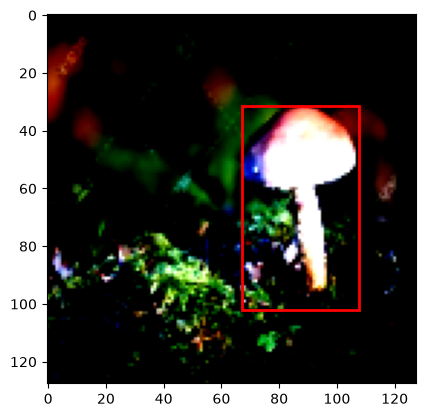

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0869353..2.3007956].


tensor(67.6643) tensor(31.2604) tensor(108.1382) tensor(102.6062)


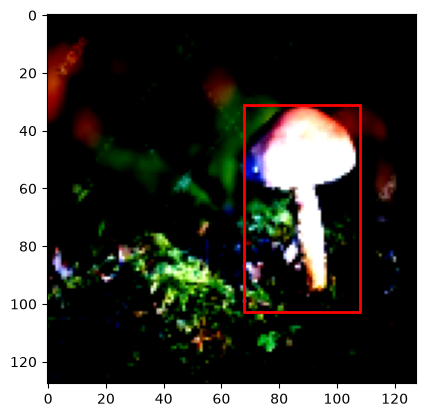

In [6]:
images,targets = next(iter(dataloader))
outputs = model(images.to(device))

show_idx = 1

print(targets[show_idx])
print(outputs[show_idx])

show_image_with_bbox(images[show_idx].cpu(), targets[show_idx].cpu())
show_image_with_bbox(images[show_idx].cpu(), outputs[show_idx].cpu().detach())

## Oefening 2: Object Detectie met PyTorch

In deze oefening gebruiken we PyTorch om object detectie uit te voeren met een pre-trained Faster R-CNN-model. Faster R-CNN (Region-Based Convolutional Neural Network) is een state-of-the-art model voor object detectie dat zowel de bounding boxes als de klassen van meerdere objecten in een afbeelding kan voorspellen.

We maken gebruik van een pre-trained Faster R-CNN-model dat beschikbaar is via de `torchvision` bibliotheek. Dit model is al getraind op de COCO dataset, dus we kunnen het gebruiken om objecten in nieuwe afbeeldingen te detecteren zonder aanvullende training.

In [ ]:
import torch
import torchvision
from torchvision.transforms import functional as F
from PIL import Image
import matplotlib.pyplot as plt
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.utils import draw_bounding_boxes
from torchvision.transforms.functional import to_pil_image

# Define helper function to display image with bounding boxes
def show_image_with_bboxes(image, bboxes, title=None):
    """Displays an image with bounding boxes."""
    plt.imshow(F.to_pil_image(image))  # Convert tensor image to PIL image for displaying
    ax = plt.gca()  # Get the current axes instance on the current figure
    
    # Draw all bounding boxes
    for bbox in bboxes.detach():
        x_min, y_min, x_max, y_max = bbox
        rect = plt.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, 
                             fill=False, edgecolor='red', linewidth=2)
        ax.add_patch(rect)

    if title:
        plt.title(title)
    plt.show()

## Oefening 3: Object Localisatie met Keras

In deze oefening implementeren we object localisatie met Keras. Net als in Oefening 1 bouwen we een eenvoudig CNN-model dat leert om de coördinaten van een bounding box te voorspellen voor een enkel object in een afbeelding. Dit model wordt getraind op een dummy dataset met willekeurige afbeeldingen en dummy bounding box-coördinaten.

Het model bestaat uit een reeks convolutie- en poolinglagen, gevolgd door volledig verbonden lagen die de bounding box-coördinaten voorspellen. We gebruiken Mean Squared Error (MSE) als de verliesfunctie om de coördinaten te trainen.

## Oefening 4: Object detectie met model van Huggingface

Een andere bron van verscheidene AI-modellen is Huggingface.
Ga nu zelf op zoek naar een model dat gebruikt kan worden om de object detectie vraag uit oefening 2 op te lossen.
De nodige stappen om het correcte model te installeren vind je ook op de site van huggingface.